# 01 · Análisis exploratorio del dataset de limones

Objetivos:
1. Entender la estructura de las anotaciones COCO.
2. Averiguar qué campos del nombre de archivo identifican a cada limón (necesario para la división por limón, #7).
3. Localizar las etiquetas de imagen (sano, verde, borrosa…) y medir el desequilibrio de clases.

In [1]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd

# Raíz del proyecto: la primera carpeta (hacia arriba) que contiene pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data" / "raw" / "lemon-dataset"
ANN_PATH = DATA_DIR / "annotations" / "instances_default.json"

coco = json.loads(ANN_PATH.read_text(encoding="utf-8"))
print("Raíz del proyecto:", ROOT)
print("Claves del JSON:", list(coco.keys()))
for key in ["images", "annotations", "categories"]:
    print(f"  {key:<12}{len(coco[key]):>7}")

Raíz del proyecto: /Users/nicolaszamoranoramirez/proyectos_programacion/agri-vision-qc
Claves del JSON: ['licenses', 'info', 'annotations', 'images', 'categories']
  images         2690
  annotations   33753
  categories        9


In [2]:
categories = pd.DataFrame(coco["categories"])
print(categories.to_string(index=False))

 id supercategory               name
  1                    image_quality
  2                          illness
  3                         gangrene
  4                            mould
  5                          blemish
  6               dark_style_remains
  7                         artifact
  8                        condition
  9                          pedicel


In [3]:
print("Ejemplo de imagen:", coco["images"][0], sep="\n  ")
print("\nCampos de una anotación:", list(coco["annotations"][0].keys()))

cat_names = dict(zip(categories["id"], categories["name"]))
attr_counts: dict[str, Counter] = {}
for ann in coco["annotations"]:
    name = cat_names[ann["category_id"]]
    for key, value in ann.get("attributes", {}).items():
        attr_counts.setdefault(name, Counter())[f"{key}={value}"] += 1

print("\nAtributos por categoría:")
for name in categories["name"]:
    print(f"  {name:<20}{dict(attr_counts.get(name, {}))}")

Ejemplo de imagen:
  {'id': 0, 'date_captured': 0, 'coco_url': '', 'file_name': 'images/0001_A_H_0_A.jpg', 'license': 0, 'flickr_url': '', 'height': 1056, 'width': 1056}

Campos de una anotación: ['id', 'iscrowd', 'area', 'category_id', 'image_id', 'segmentation', 'bbox']

Atributos por categoría:
  image_quality       {}
  illness             {}
  gangrene            {}
  mould               {}
  blemish             {}
  dark_style_remains  {}
  artifact            {}
  condition           {}
  pedicel             {}


In [4]:
images = pd.DataFrame(coco["images"])
partes = images["file_name"].map(lambda f: Path(f).stem.split("_"))
print("Número de campos por nombre:")
print(partes.map(len).value_counts().to_string())

campos = pd.DataFrame(partes.tolist(), index=images.index).add_prefix("campo_")
images = images.join(campos)
print("\nValores distintos por campo:")
for col in campos.columns:
    valores = images[col].value_counts().sort_index()
    muestra = ", ".join(f"{v} ({n})" for v, n in valores.head(12).items())
    print(f"  {col}: {images[col].nunique()} distintos -> {muestra}{' ...' if len(valores) > 12 else ''}")

Número de campos por nombre:
file_name
5    2690

Valores distintos por campo:
  campo_0: 35 distintos -> 0001 (110), 0002 (120), 0003 (197), 0004 (185), 0005 (152), 0006 (85), 0007 (58), 0008 (40), 0009 (66), 0010 (62), 0011 (102), 0012 (129) ...
  campo_1: 7 distintos -> A (809), B (287), C (591), D (305), E (194), F (247), G (257)
  campo_2: 4 distintos -> H (1032), I (852), V (800), Y (6)
  campo_3: 12 distintos -> 0 (222), 105 (216), 120 (224), 135 (231), 15 (221), 150 (225), 165 (229), 30 (224), 45 (234), 60 (225), 75 (220), 90 (219)
  campo_4: 9 distintos -> A (747), B (120), C (539), D (84), E (22), F (369), G (666), H (121), [F (22)


In [5]:
for combo in (["campo_0"], ["campo_0", "campo_1"], ["campo_0", "campo_1", "campo_2"]):
    grupos = images.groupby(combo).size()
    print(f"\nAgrupando por {' + '.join(combo)}: {len(grupos)} grupos")
    print("  fotos por grupo -> " + ", ".join(
        f"{k}: {v:.1f}" for k, v in grupos.describe()[["min", "50%", "mean", "max"]].items()))

grupos3 = images.groupby(["campo_0", "campo_1", "campo_2"])
primero = next(iter(grupos3.groups))
print(f"\nFotos del primer grupo {primero}:")
print(grupos3.get_group(primero)[["file_name", "campo_3", "campo_4"]].to_string(index=False))


Agrupando por campo_0: 35 grupos
  fotos por grupo -> min: 5.0, 50%: 66.0, mean: 76.9, max: 197.0

Agrupando por campo_0 + campo_1: 117 grupos
  fotos por grupo -> min: 1.0, 50%: 23.0, mean: 23.0, max: 65.0

Agrupando por campo_0 + campo_1 + campo_2: 264 grupos
  fotos por grupo -> min: 1.0, 50%: 12.0, mean: 10.2, max: 24.0

Fotos del primer grupo ('0001', 'A', 'H'):
              file_name campo_3 campo_4
images/0001_A_H_0_A.jpg       0       A


## 2. Qué identifica a cada limón

Ninguna combinación de campos da grupos de 12 fotos exactas, aunque el README dice que el número identifica a cada fruta. Lo comprobamos mirando las imágenes.

In [6]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

AZUL = "#257de0"  # un solo color para gráficos de una sola serie

images = images.rename(columns={
    "campo_0": "numero", "campo_1": "lote", "campo_2": "orientacion",
    "campo_3": "angulo", "campo_4": "posicion",
})
images["angulo"] = images["angulo"].astype(int)
images["nombre"] = images["file_name"].map(lambda f: Path(f).stem)


def mostrar(nombres, columnas=6, tam=2.2):
    """Muestra una cuadrícula de imágenes del dataset con su nombre encima."""
    nombres = list(nombres)
    filas = -(-len(nombres) // columnas)  # división redondeando hacia arriba
    fig, axes = plt.subplots(filas, columnas, figsize=(columnas * tam, filas * (tam + 0.3)), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, nombre in zip(axes.flat, nombres):
        ax.imshow(Image.open(DATA_DIR / "images" / f"{nombre}.jpg"))
        ax.set_title(nombre, fontsize=8)
    plt.tight_layout()
    plt.show()


print(images[["nombre", "numero", "lote", "orientacion", "angulo", "posicion"]].head(3).to_string(index=False))

        nombre numero lote orientacion  angulo posicion
  0001_A_H_0_A   0001    A           H       0        A
0003_A_V_150_A   0003    A           V     150        A
 0003_A_V_15_A   0003    A           V      15        A


A) El mismo número (0001) en distintos lotes:


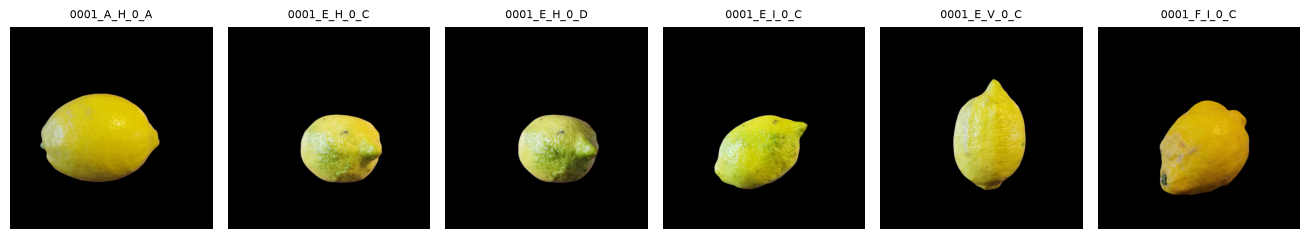

B) Un mismo lote y número (0003_B) con distintas orientaciones y posiciones:


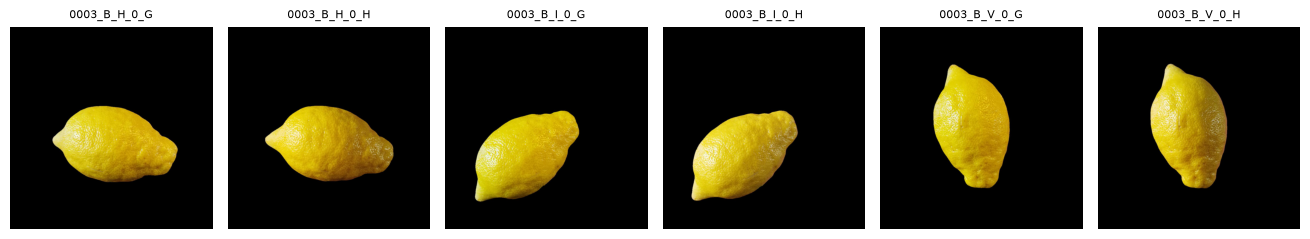

C) Una secuencia completa: 0003_B, orientación H, posición G, todos sus ángulos:


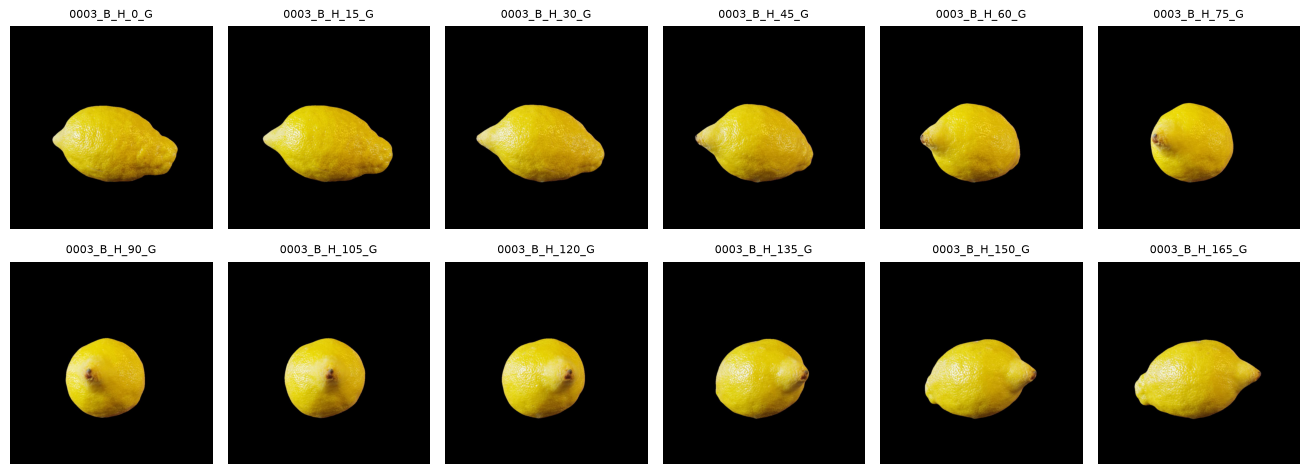

In [7]:
a0 = images[images["angulo"] == 0]

print("A) El mismo número (0001) en distintos lotes:")
mostrar(a0[a0["numero"] == "0001"].sort_values("nombre")["nombre"].head(6))

print("B) Un mismo lote y número (0003_B) con distintas orientaciones y posiciones:")
mostrar(a0[(a0["numero"] == "0003") & (a0["lote"] == "B")].sort_values("nombre")["nombre"])

print("C) Una secuencia completa: 0003_B, orientación H, posición G, todos sus ángulos:")
vuelta = images[(images["numero"] == "0003") & (images["lote"] == "B")
                & (images["orientacion"] == "H") & (images["posicion"] == "G")]
mostrar(vuelta.sort_values("angulo")["nombre"])

**Resultado de la comprobación visual:**
- `numero`: número del limón **dentro de su lote**. La numeración se reinicia en cada lote: el 0001 del lote A y el del lote G son limones distintos.
- `lote`: paquete de origen (A–G).
- `orientacion`: cómo se colocó el limón: H (horizontal), I (inclinado), V (vertical).
- `angulo`: giro del limón en la plataforma, de 0 a 165° en pasos de 15° (12 fotos por secuencia).
- `posicion`: montaje de luz. Van por parejas con el mismo encuadre y distinta iluminación: A/B, C/D, G/H y F/[F (la segunda, más oscura). Ver sección 4.

**Un limón = `lote` + `numero`.** La división train/val/test (#7) se hará con este identificador.    

In [8]:
images["limon"] = images["lote"] + "_" + images["numero"]
fotos = images.groupby("limon").size()
print(f"Limones: {images['limon'].nunique()}  |  fotos por limón: "
      f"mín {fotos.min()}, mediana {fotos.median():.0f}, máx {fotos.max()}")

secuencias = images.groupby(["limon", "orientacion", "posicion"])["angulo"]
repetidos = secuencias.apply(lambda a: a.duplicated().any()).sum()
print(f"Secuencias (limón + orientación + posición): {secuencias.ngroups}"
      f"  |  con algún ángulo repetido: {repetidos}")

print("\nValores raros:")
for columna, valor in [("posicion", "[F"), ("orientacion", "Y")]:
    raras = images[images[columna] == valor]
    print(f"  {columna} = '{valor}': {len(raras)} fotos, limón(es) {sorted(raras['limon'].unique())}")

Limones: 117  |  fotos por limón: mín 1, mediana 23, máx 65
Secuencias (limón + orientación + posición): 322  |  con algún ángulo repetido: 0

Valores raros:
  posicion = '[F': 22 fotos, limón(es) ['G_0020']
  orientacion = 'Y': 6 fotos, limón(es) ['D_0009']


## 3. Etiquetas: qué defectos hay, cuántos y dónde

In [9]:
ann = pd.DataFrame(coco["annotations"])
ann["categoria"] = ann["category_id"].map(cat_names)
ann["lado_px"] = ann["bbox"].map(lambda b: max(b[2], b[3]))  # lado mayor de la caja, en píxeles

DEFECTOS = ["illness", "gangrene", "mould", "blemish", "dark_style_remains"]
conteo = ann.pivot_table(index="image_id", columns="categoria", values="id", aggfunc="count", fill_value=0)
# drop(...) evita un error si se vuelve a ejecutar esta celda sin reiniciar
images = images.drop(columns=conteo.columns, errors="ignore").join(conteo, on="id")
images[list(conteo.columns)] = images[list(conteo.columns)].fillna(0).astype(int)

images["con_defecto"] = images[DEFECTOS].sum(axis=1) > 0
images["podredumbre"] = (images["mould"] > 0) | (images["gangrene"] > 0)
limones = images.groupby("limon").agg(
    lote=("lote", "first"), fotos=("id", "size"),
    con_defecto=("con_defecto", "any"), podredumbre=("podredumbre", "any"),
)

print(f"Imágenes sin ninguna región anotada: {(images[list(conteo.columns)].sum(axis=1) == 0).sum()}")
print(f"Imágenes con algún defecto: {images['con_defecto'].sum()} de {len(images)}")
print(f"Limones con algún defecto:  {limones['con_defecto'].sum()} de {len(limones)}")
print(f"\nImágenes con podredumbre (moho o gangrena): {images['podredumbre'].sum()} de {len(images)}")
print(f"Limones con podredumbre:                    {limones['podredumbre'].sum()} de {len(limones)}")
frac = images[images["limon"].isin(limones.index[limones["podredumbre"]])].groupby("limon")["podredumbre"].mean()
print(f"En los limones con podredumbre, se ve en el {frac.mean():.0%} de sus fotos (media)")

Imágenes sin ninguna región anotada: 0
Imágenes con algún defecto: 2566 de 2690
Limones con algún defecto:  117 de 117

Imágenes con podredumbre (moho o gangrena): 684 de 2690
Limones con podredumbre:                    54 de 117
En los limones con podredumbre, se ve en el 57% de sus fotos (media)


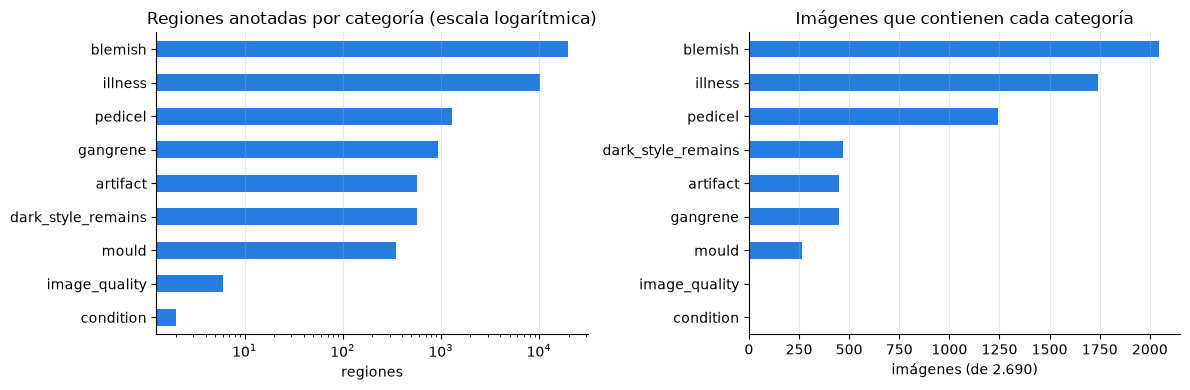

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ann["categoria"].value_counts().sort_values().plot.barh(ax=ax1, color=AZUL)
ax1.set_xscale("log")
ax1.set_title("Regiones anotadas por categoría (escala logarítmica)")
ax1.set_xlabel("regiones")
(images[list(conteo.columns)] > 0).sum().sort_values().plot.barh(ax=ax2, color=AZUL)
ax2.set_title("Imágenes que contienen cada categoría")
ax2.set_xlabel("imágenes (de 2.690)")
for ax in (ax1, ax2):
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
por_lote = (images[DEFECTOS] > 0).groupby(images["lote"]).sum()
por_lote.insert(0, "limones", limones.groupby("lote").size())
por_lote["limones_podridos"] = limones.groupby("lote")["podredumbre"].sum()
print("Imágenes que contienen cada defecto, por lote:")
print(por_lote.to_string())

Imágenes que contienen cada defecto, por lote:
      limones  illness  gangrene  mould  blemish  dark_style_remains  limones_podridos
lote                                                                                  
A          28      445        23      0      494                  64                 5
B          13      201        37     19      226                 237                 7
C          26      409       133      4      568                  44                13
D          21      169        28      0      290                  59                 5
E           8      188        59      0      100                  37                 4
F           9      179       141      1      244                  26                 8
G          12      152        28    240      126                   0                12


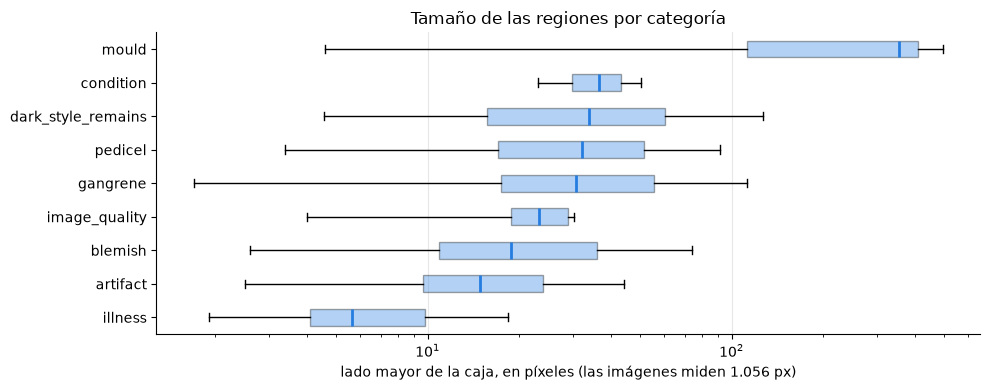

Mediana del lado mayor (px):
categoria
illness                 6
artifact               15
blemish                19
image_quality          23
gangrene               31
pedicel                32
dark_style_remains     34
condition              37
mould                 355


In [12]:
orden = ann.groupby("categoria")["lado_px"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([ann.loc[ann["categoria"] == c, "lado_px"] for c in orden],
           tick_labels=list(orden), orientation="horizontal", showfliers=False,
           patch_artist=True, boxprops={"facecolor": AZUL, "alpha": 0.35},
           medianprops={"color": AZUL, "linewidth": 2})
ax.set_xscale("log")
ax.set_xlabel("lado mayor de la caja, en píxeles (las imágenes miden 1.056 px)")
ax.set_title("Tamaño de las regiones por categoría")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print("Mediana del lado mayor (px):")
print(ann.groupby("categoria")["lado_px"].median().round().astype(int).sort_values().to_string())

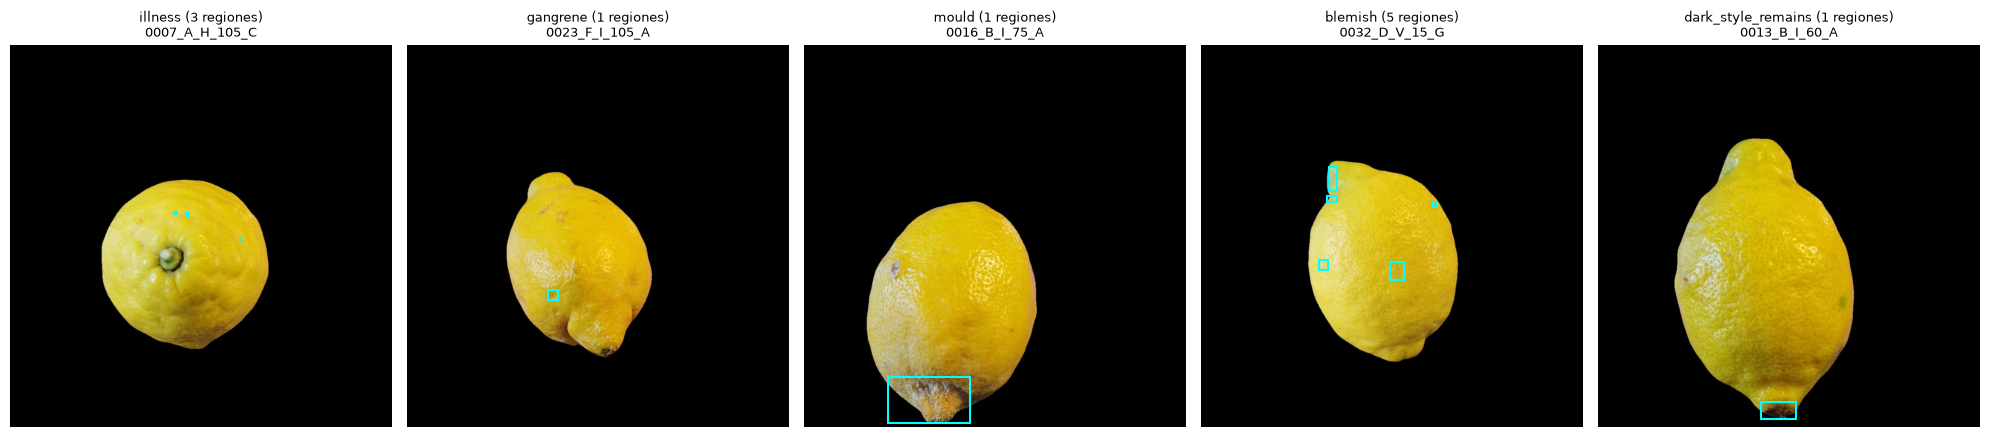

In [13]:
fig, axes = plt.subplots(1, len(DEFECTOS), figsize=(4 * len(DEFECTOS), 4.5))
for ax, defecto in zip(axes, DEFECTOS):
    candidatas = images[images[defecto] > 0].sort_values([defecto, "nombre"])
    fila = candidatas.iloc[len(candidatas) // 2]  # una imagen "típica": la mediana
    ax.imshow(Image.open(DATA_DIR / fila["file_name"]))
    cajas = ann.loc[(ann["image_id"] == fila["id"]) & (ann["categoria"] == defecto), "bbox"]
    for x, y, w, h in cajas:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="cyan", linewidth=1.5))
    ax.set_title(f"{defecto} ({len(cajas)} regiones)\n{fila['nombre']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Iluminación: qué cambia entre posiciones

En la comprobación visual, las posiciones G y H parecían iguales salvo por la luz. Lo medimos en todas las imágenes con el brillo medio de los píxeles del limón (el fondo negro se descarta).

In [14]:
import numpy as np
from tqdm import tqdm


def brillo_limon(ruta):
    """Brillo medio (0-255) de los píxeles del limón; el fondo negro se descarta."""
    rgb = np.asarray(Image.open(ruta).convert("RGB").resize((132, 132)), dtype=float)
    luminancia = rgb @ [0.2126, 0.7152, 0.0722]
    return luminancia[rgb.max(axis=2) > 40].mean()


images["brillo"] = [brillo_limon(DATA_DIR / f) for f in tqdm(images["file_name"])]

print("Brillo medio del limón por posición:")
print(images.groupby("posicion")["brillo"].agg(["count", "mean"]).round(1).to_string())

# Pares de fotos idénticas salvo la posición: mismo limón, orientación y ángulo
pares = (images.groupby(["limon", "orientacion", "angulo"]).filter(lambda g: len(g) == 2)
         .sort_values(["limon", "orientacion", "angulo", "posicion"]))
resumen = pares.groupby(["limon", "orientacion", "angulo"]).agg(
    par=("posicion", lambda p: " -> ".join(p)),
    diferencia=("brillo", lambda b: b.iloc[1] - b.iloc[0]),
)
print("\nCambio de brillo entre las dos fotos de cada par:")
print(resumen.groupby("par")["diferencia"].agg(
    pares="count", media="mean", mas_oscura=lambda d: f"{(d < 0).mean():.0%}").round(1).to_string())

print("\nBrillo medio por lote:")
print(images.groupby("lote")["brillo"].mean().round(1).to_string())

  0%|          | 0/2690 [00:00<?, ?it/s]

100%|██████████| 2690/2690 [00:08<00:00, 299.64it/s]


Brillo medio del limón por posición:
          count   mean
posicion              
A           747  163.5
B           120  154.3
C           539  168.0
D            84  153.0
E            22  140.7
F           369  134.7
G           666  171.0
H           121  161.4
[F           22  131.0

Cambio de brillo entre las dos fotos de cada par:
         pares  media mas_oscura
par                             
A -> B     106  -16.1       100%
C -> D      76  -17.2       100%
F -> [F      4   -5.8       100%
G -> H     118  -10.8        95%

Brillo medio por lote:
lote
A    163.9
B    164.3
C    162.9
D    162.7
E    167.1
F    161.2
G    136.9


## 5. Conclusiones

**Estructura**
- 2.690 imágenes de **117 limones** de 7 lotes (A–G), con entre 1 y 65 fotos por limón.
- Un limón se identifica por **lote + número**: la numeración se reinicia en cada lote.
- Cada secuencia son 12 ángulos (0–165°) con una orientación (H, I, V) y una posición. Las posiciones van por parejas con el mismo encuadre y distinta luz: A/B, C/D, G/H y F/[F.
- Valores raros: `[F` (22 fotos, limón G_0020) e `Y` (6 fotos, limón D_0009, probablemente V).

**Etiquetas**
- El COCO no incluye las etiquetas de imagen del README (healthy, greening, blurry…): se perdieron al exportar.
- `condition` (2) e `image_quality` (6) son regiones sueltas y se descartan. `pedicel` y `artifact` no son defectos.
- Los 117 limones tienen algún defecto, casi siempre manchas (`blemish`) o puntos (`illness`): **no hay clase "sano"**.
- Etiqueta viable: **podredumbre** (moho o gangrena), presente en 54 de 117 limones y 684 de 2.690 imágenes. En un limón podrido solo se ve en el 57 % de sus fotos.

**Riesgos para el modelo**
- **Fuga de datos:** dividir por limón, nunca por foto.
- **Atajo del lote G:** sus 12 limones están podridos, concentra casi todo el moho y se fotografió con menos luz (brillo medio 137 frente a ~163). Un modelo podría aprender la luz en vez del defecto.
- **Defectos diminutos:** `illness` mide unos 6 px en imágenes de 1.056 px.

Decisión sobre el primer modelo: ADR 002 en `docs/decisiones.md`.